# 1982 — Hopfield Networks (Associative Memory)

**Paper:** John Hopfield, *"Neural networks and physical systems with emergent collective computational abilities"* (1982). (Nobel Prize in Physics 2024, shared with Geoffrey Hinton.)

A fully connected network of $\pm1$ neurons with **symmetric** weights stores patterns as **minima of an energy function**:

$$E(s) = -\tfrac12 \sum_{i\neq j} W_{ij} s_i s_j, \qquad W = \frac1N \sum_\mu \xi^\mu {\xi^\mu}^\top,\ W_{ii}=0 \quad\text{(Hebbian rule)}$$

Asynchronous updates $s_i \leftarrow \operatorname{sign}(\sum_j W_{ij}s_j)$ never increase $E$, so a corrupted pattern "rolls downhill" to the stored memory. Capacity is about $0.138\,N$ random patterns.

![Diagram: Hopfield network (1982)](https://raw.githubusercontent.com/babushkai/neuralnetwork/main/assets/diagrams/06_1982_hopfield_network.png)

In [1]:
import numpy as np
import matplotlib.pyplot as plt
rng = np.random.default_rng(0)

## Patterns: 10×10 letters

In [2]:
art = {
"H": ["#........#","#........#","#........#","#........#","##########","##########","#........#","#........#","#........#","#........#"],
"O": ["..######..",".#......#.","#........#","#........#","#........#","#........#","#........#","#........#",".#......#.","..######.."],
"P": ["########..","#.......#.","#........#","#.......#.","########..","#.........","#.........","#.........","#.........","#........."],
"F": ["##########","#.........","#.........","#.........","#######...","#.........","#.........","#.........","#.........","#........."],
}
patterns = np.array([[1 if c == "#" else -1 for row in a for c in row] for a in art.values()])
N = patterns.shape[1]
print("patterns:", patterns.shape)

patterns: (4, 100)


In [3]:
class Hopfield:
    def __init__(self, n):
        self.W = np.zeros((n, n))

    def store(self, P):
        self.W = P.T @ P / P.shape[1]
        np.fill_diagonal(self.W, 0)

    def energy(self, s):
        return -0.5 * s @ self.W @ s

    def recall(self, s, sweeps=10):
        s = s.copy(); energies = [self.energy(s)]
        for _ in range(sweeps):
            changed = False
            for i in rng.permutation(len(s)):                # asynchronous updates
                new = 1 if self.W[i] @ s >= 0 else -1
                if new != s[i]:
                    s[i] = new; changed = True
            energies.append(self.energy(s))
            if not changed:
                break
        return s, energies

net = Hopfield(N)
net.store(patterns)

## Recall from 30% corrupted inputs

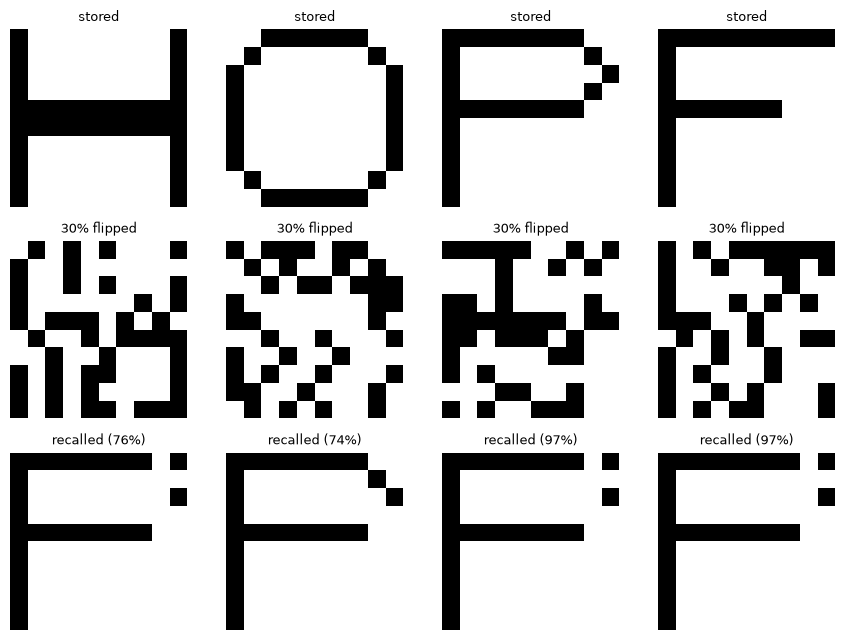

In [4]:
def corrupt(p, frac):
    s = p.copy(); idx = rng.choice(len(p), int(frac * len(p)), replace=False); s[idx] *= -1; return s

fig, axes = plt.subplots(3, len(patterns), figsize=(2.2 * len(patterns), 6.5))
for k, p in enumerate(patterns):
    noisy = corrupt(p, 0.3)
    out, E = net.recall(noisy)
    for r, (img, t) in enumerate([(p, "stored"), (noisy, "30% flipped"), (out, f"recalled ({(out == p).mean():.0%})")]):
        axes[r, k].imshow(img.reshape(10, 10), cmap="gray_r"); axes[r, k].set_title(t, fontsize=9); axes[r, k].axis("off")
plt.tight_layout(); plt.show()

## Energy only goes down

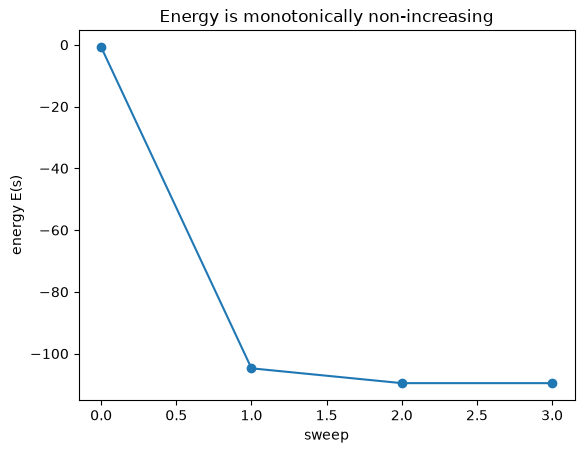

In [5]:
_, E = net.recall(corrupt(patterns[0], 0.4), sweeps=10)
plt.plot(E, marker="o"); plt.xlabel("sweep"); plt.ylabel("energy E(s)"); plt.title("Energy is monotonically non-increasing"); plt.show()

## Capacity: how many random patterns can N=100 neurons store?
Theory predicts breakdown around $0.138N \approx 14$ patterns.

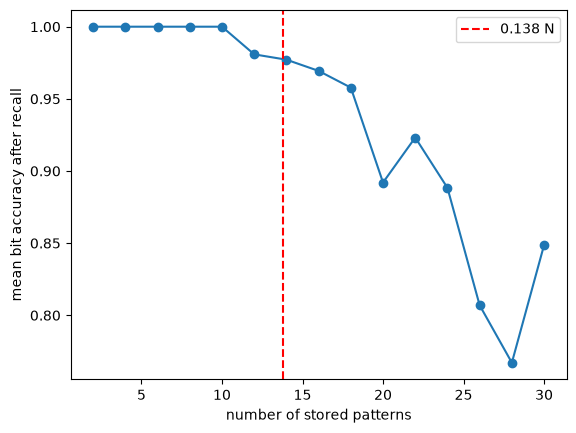

In [6]:
N2 = 100
results = []
for P in range(2, 31, 2):
    pats = rng.choice([-1, 1], size=(P, N2))
    h = Hopfield(N2); h.store(pats)
    acc = np.mean([(h.recall(corrupt(p, 0.05), sweeps=5)[0] == p).mean() for p in pats])
    results.append((P, acc))
P_, A_ = zip(*results)
plt.plot(P_, A_, marker="o"); plt.axvline(0.138 * N2, ls="--", c="r", label="0.138 N")
plt.xlabel("number of stored patterns"); plt.ylabel("mean bit accuracy after recall"); plt.legend(); plt.show()

## Takeaways
- Memory as **energy minima** — connecting neural networks with statistical physics.
- *Modern Hopfield networks* (2020) use an exponential energy with exponentially larger capacity, and their update rule is exactly transformer attention.